In [1]:
import dataclasses
import typing as t

import numpy as np
import xarray as xr

# Approximate Earth radius in meters (needed for circumference calculation)
EARTH_RADIUS_M = 6371000.0

@dataclasses.dataclass
class DerivedVariable:
    """Derived variable base class."""
    @property
    def base_variables(self) -> list[str]:
        return []

    @property
    def core_dims(self) -> t.Tuple[t.Tuple[t.List[str], ...], t.List[str]]:
        raise NotImplementedError

    def compute(self, dataset: xr.Dataset) -> xr.DataArray:
        raise NotImplementedError

@dataclasses.dataclass
class ZonalEnergySpectrum(DerivedVariable):
    """Compute energy spectrum along the zonal direction for a given variable."""
    variable_name: str

    @property
    def base_variables(self) -> list[str]:
        return [self.variable_name]

    @property
    def core_dims(self) -> t.Tuple[t.Tuple[t.List[str], ...], t.List[str]]:
        return (['longitude'],), ['zonal_wavenumber']

    def _circumference(self, dataset: xr.Dataset) -> xr.DataArray:
        """Earth's circumference as a function of latitude."""
        circum_at_equator = 2 * np.pi * EARTH_RADIUS_M
        return np.cos(dataset.latitude * np.pi / 180) * circum_at_equator

    def lon_spacing_m(self, dataset: xr.Dataset) -> xr.DataArray:
        """Spacing (meters) between longitudinal values in `dataset`."""
        diffs = dataset.longitude.diff('longitude')
        if np.max(np.abs(diffs - diffs[0])) > 1e-3:
            raise ValueError(
                f'Expected uniform longitude spacing. {dataset.longitude.values=}'
            )
        return self._circumference(dataset) * diffs[0].data / 360

    def compute(self, dataset: xr.Dataset) -> xr.DataArray:
        """Computes zonal power at wavenumber and frequency."""
        spacing = self.lon_spacing_m(dataset)

        def simple_power(f_x):
            f_k = np.fft.rfft(f_x, axis=-1, norm='forward')
            # freq > 0 should be counted twice in power since it accounts for both
            # positive and negative frequency components
            one_and_many_twos = np.concatenate(([1], [2] * (f_k.shape[-1] - 1)))
            return np.real(f_k * np.conj(f_k)) * one_and_many_twos

        # Apply the FFT-based power calculation along 'longitude'
        spectrum = xr.apply_ufunc(
            simple_power,
            dataset[self.variable_name],
            input_core_dims=[['longitude']],
            output_core_dims=[['zonal_wavenumber']],
            exclude_dims={'longitude'},
        )

        # Assign coordinates
        spectrum = spectrum.assign_coords(
            zonal_wavenumber=('zonal_wavenumber', spectrum.zonal_wavenumber.data)
        )
        base_frequency = xr.DataArray(
            np.fft.rfftfreq(dataset.sizes['longitude']),
            dims='zonal_wavenumber',
            coords={'zonal_wavenumber': spectrum.zonal_wavenumber}
        )
        spectrum = spectrum.assign_coords(frequency=base_frequency / spacing)
        spectrum['frequency'] = spectrum.frequency.assign_attrs(units='1 / m')

        spectrum = spectrum.assign_coords(wavelength=1 / spectrum.frequency)
        spectrum['wavelength'] = spectrum.wavelength.assign_attrs(units='m')

        # Scale by circumference so that the sum of spectra equals spatial integral of |f|²
        return spectrum * self._circumference(spectrum)

In [2]:
time = np.arange(np.datetime64('2020-01-01'), np.datetime64('2020-01-11'))
latitude = np.linspace(-90, 90, 32)
longitude = np.linspace(0, 360, 64, endpoint=False)

# Synthetic geopotential data (random values)
data = np.random.rand(len(time), len(latitude), len(longitude)) * 10000.0

ds = xr.Dataset(
    {
        'geopotential': (['time', 'latitude', 'longitude'], data)
    },
    coords={
        'time': time,
        'latitude': latitude,
        'longitude': longitude
    }
)

<ipython-input-2-99d1f02c2cdc>:12: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  ds = xr.Dataset(


In [3]:
ds

<xarray.Dataset> Size: 165kB
Dimensions:       (time: 10, latitude: 32, longitude: 64)
Coordinates:
  * time          (time) datetime64[ns] 80B 2020-01-01 2020-01-02 ... 2020-01-10
  * latitude      (latitude) float64 256B -90.0 -84.19 -78.39 ... 84.19 90.0
  * longitude     (longitude) float64 512B 0.0 5.625 11.25 ... 343.1 348.8 354.4
Data variables:
    geopotential  (time, latitude, longitude) float64 164kB 2.705e+03 ... 4.9...

In [4]:
# Instantiate the zonal energy spectrum for 'geopotential'
zonal_es = ZonalEnergySpectrum('geopotential')

# Compute the spectrum at a given time slice to demonstrate
# (you can also compute over all times if desired)
# Here we pick the first time-step just as an example
spectrum = zonal_es.compute(ds.isel(time=0))

print("Zonal Energy Spectrum for 'geopotential' at first time step:")
print(spectrum)

Zonal Energy Spectrum for 'geopotential' at first time step:
<xarray.DataArray (latitude: 32, zonal_wavenumber: 33)> Size: 8kB
array([[6.32623556e-02, 8.40308650e-04, 2.09414829e-03, ...,
        1.81809897e-03, 1.40751368e-04, 3.90729453e-05],
       [1.05161758e+14, 2.50180676e+12, 1.27712353e+12, ...,
        1.59507659e+11, 2.32249906e+12, 7.65867106e+11],
       [1.64085187e+14, 1.61106569e+12, 1.04800593e+12, ...,
        2.44032273e+12, 8.99959896e+11, 3.16317407e+12],
       ...,
       [2.49936572e+14, 1.01596468e+13, 1.79760659e+12, ...,
        6.77927752e+11, 5.64389663e+11, 5.23039662e+11],
       [9.93131648e+13, 2.67039165e+12, 5.66498283e+12, ...,
        1.20700013e+12, 3.42791852e+11, 1.04122711e+11],
       [6.73939510e-02, 2.62863363e-03, 6.38759597e-04, ...,
        1.67957249e-03, 1.59472634e-03, 2.32187659e-05]])
Coordinates:
    time              datetime64[ns] 8B 2020-01-01
  * latitude          (latitude) float64 256B -90.0 -84.19 -78.39 ... 84.19 90.0
  * zon

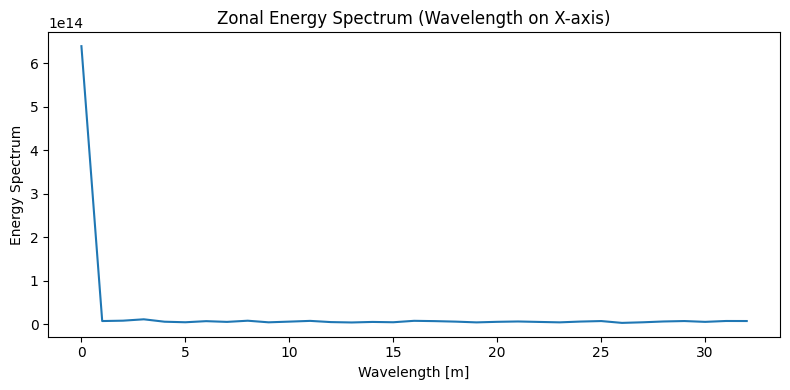

In [7]:
import matplotlib.pyplot as plt
spectrum_wavelength = spectrum.mean(dim='latitude').swap_dims({'zonal_wavenumber': 'wavelength'})

plt.figure(figsize=(8, 4))
spectrum_wavelength.plot()
plt.title('Zonal Energy Spectrum (Wavelength on X-axis)')
plt.xlabel('Wavelength [m]')
plt.ylabel('Energy Spectrum')
plt.tight_layout()
plt.show()